# 2023年Java大厂面试｜02：Redis缓存、分布式锁与集群

> 学习目标：能从真实项目解释Redis的使用场景，区分缓存故障，说明一致性、持久化、内存管理、锁与集群的机制，并回答它们的失败边界。

**主要依据：** `5.2023版Java面试教程/02-Redis篇/PPT/02-Redis篇.pptx`，共85页。已读取全部文字、组合形状和表格，并查看嵌入的代码与面试问答截图。第84页为讲师介绍，第85页为空白。

视频目录共14节，仅核对文件名，未观看或转写。`在线讲义文稿.txt`内容是一个飞书链接；已访问链接，但只加载到“面试专题”标题和占位区域，未读取其正文。因此本篇不声称覆盖视频补充或在线讲义全文。

课件终端截图出现Redis 6.2.4，也讨论Redis 6.0之后的I/O线程。“课件要点”表示原资料内容；“补充说明”“修正”表示整理者补充的机制、代码改写或适用条件。Redisson和部署参数需要结合实际版本核对。

### 目录

- 1～2：使用场景、数据类型与缓存基本流程
- 3～7：穿透、布隆过滤器、击穿、逻辑过期、雪崩
- 8～11：数据库与缓存一致性、双删、异步通知、读写锁
- 12～16：RDB、AOF、恢复、过期与淘汰
- 17～20：抢券并发、Redis锁、Redisson、故障边界
- 21～25：部署方案、主从复制、Sentinel、脑裂、Cluster
- 26～28：事务补充、Redis性能、I/O模型
- 29～31：练习、面试自测、来源与覆盖范围

所有命令与代码均为学习示例，本篇没有运行Redis实例、部署集群或完成压力测试。课件中的项目口吻和数字不能作为自己的工作经历或实测结果。


## 1. Redis使用场景与项目回答

**课件第2～5页：** 场景包括缓存、分布式锁、计数器、保存token、消息队列和延迟队列。面试常从“最近项目哪些地方用了Redis”开始，继续询问数据类型、缓存故障和部署方式。

**补充映射：** 下表用于把业务与数据结构联系起来，不表示每种用途都只对应一种类型。

| 类型或能力 | 典型用途 | 需要继续考虑的边界 |
|---|---|---|
| String | 缓存JSON、token、INCR计数 | 序列化、TTL、大小、并发复合操作 |
| Hash | 按字段保存对象、Redisson锁状态 | 字段与整个key的生命周期、版本支持 |
| List | 简单队列、按顺序消费 | 消费失败、消息重投、阻塞取值的行为 |
| Set | 去重、成员关系、参与记录 | 内存、集合规模、重复操作语义 |
| Sorted Set/ZSet | 排行榜、按时间评分的延迟任务 | 并发领取、过期任务、重试与排序规则 |
| Bitmap | 签到、状态标记 | ID分布、位偏移、稀疏空间浪费 |
| Stream（补充） | 消息记录、消费组 | 确认、待处理记录、重投和裁剪 |

Redis可以实现队列，但可靠性取决于具体类型与协议。不能把List、ZSet、Stream与专业消息中间件的消费确认、重试、积压和存储能力视为完全等价。

**回答模板：**

> 在____学习/工作项目中，Redis用于____。key设计是____，value使用____类型。数据来源和写入流程为____，TTL或淘汰策略为____。出现____问题时，采用____处理，验证依据是____。

只填写自己做过的范围。一个能解释正常与失败链路的场景，比罗列所有Redis用途更能支持追问。


## 2. 缓存基本流程与原子性

**课件第6、22页：** 查询先读缓存，未命中再查数据库，写入缓存后返回。常称为Cache Aside，即应用负责在数据库与缓存之间组织读写。

~~~text
请求 → 参数与权限校验 → 查缓存
                        ├─ 有值：返回
                        └─ 无值：查数据库 → 回填缓存并设置TTL → 返回
~~~

缓存key示例为`article:123`，业务类型与ID一起组成key。value可以是序列化对象；缓存对象与数据库记录并不自动形成事务。

**补充命令示例，未执行：**

~~~redis
SET demo:article:123 '{"id":123,"title":"示例"}' EX 300
GET demo:article:123
TTL demo:article:123
~~~

`EX`表示秒，`PX`表示毫秒。设置value与TTL尽量在同一条命令中完成，避免写值成功、设置过期失败。课件中的`set name heima 10`不是正确的TTL写法，应写为`SET name heima EX 10`。

**原子性要点：** 单条命令原子执行，不代表连续执行GET、判断、SET也原子。Java应用中的判断发生在Redis之外，多客户端请求可能交错。

缓存首先需要定义新鲜度要求：允许返回多旧的数据？哪个系统保存权威结果？如果缓存失败，是否可以回源？带着这些条件再讨论一致性方案。


## 3. 缓存穿透与空结果缓存

**课件第6～12页：** 请求的数据在缓存和数据库中都不存在；若空结果不缓存，每次请求仍会查库，这就是缓存穿透的一类典型场景。

~~~text
重复查询不存在的ID
  → 缓存无值 → 数据库无记录 → 未回填 → 下次再次查数据库
~~~

### 方案一：缓存空结果

缓存一个“已查过、确实不存在”的标记，并给它较短TTL。要区分“缓存未命中”与“命中了空结果”。

~~~text
GET key
  无key：允许查库
  命中空标记：返回不存在
  命中真实数据：返回数据
~~~

**修正：** 课件`{key:1,value:null}`是概念表示。Redis String不能直接保存Java的null，应使用明确的哨兵值、结构或序列化约定，并避免它与合法数据冲突。

优点是实现简单，能降低重复查同一个不存在ID的成本。代价是占用内存，且新数据创建后，旧空标记可能暂时遮挡真实数据。短TTL、新增后的失效处理可以降低这一问题。

### 方案二：布隆过滤器

在查缓存或数据库之前，筛掉确定不在已维护集合中的ID，下一节展开。

**补充：** 参数格式与范围校验、权限校验、限流也有帮助。穿透并不必然说明遭到攻击，错误调用或正常查询已删除对象同样可能触发。缓存空值也不能阻止无限不同ID持续消耗内存。


## 4. 布隆过滤器的原理与误判

**课件第7～11页：** 布隆过滤器用位图和多个哈希位置描述集合。位图中的每个位为0或1。

1. 插入元素时，通过多个哈希计算得到位下标，把对应位设置为1。
2. 查询时计算同样的位置。只要有一位为0，可判断该元素不在集合中。
3. 如果对应位全为1，只能判断“可能存在”，仍需继续查缓存或数据库。

~~~text
元素A：设置位置1、3、7
元素B：设置位置9、12、14
不存在的元素C若碰巧落在已置1的位置，也可能返回“存在”
~~~

**补充条件：** 在元素已正确加入、没有丢更新且未进行不支持的删除时，经典布隆过滤器通常不会把已加入元素判为不存在。实际系统若过滤器没同步新增数据、重建不完整，仍会误拦截。

普通布隆过滤器不能随意把一个元素对应位清零，因为其他元素可能共享这些位。需要删除功能时，应选择相应结构或重建策略。

### 误判与实现

课件介绍Redisson和Guava，并展示`tryInit(size, 0.05)`，先加入`add0`至`add(size-1)`，再测试下一段未加入的数据。

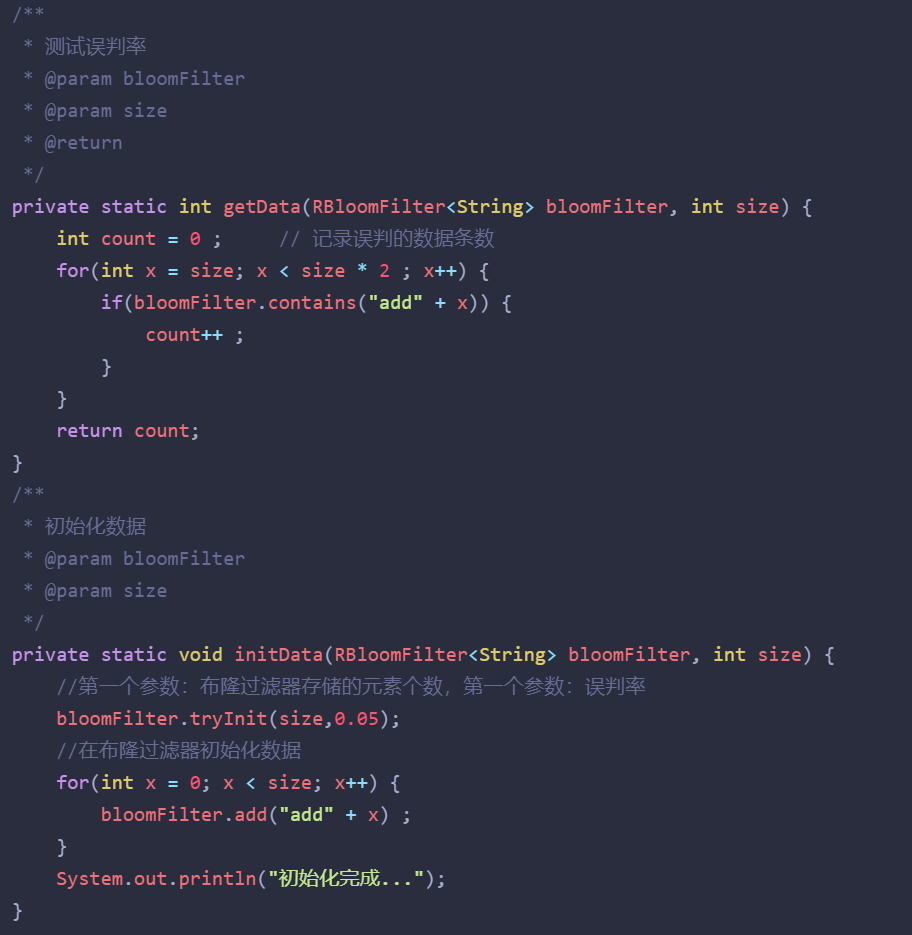

`0.05`是例子中的目标误判率，不是所有业务都适用的固定值。哈希次数也不固定为3次。元素规模、位图长度、哈希数量共同影响误判与成本。

**补充计算方法：** 测试误判率＝不存在的测试元素中返回“可能存在”的数量÷不存在的测试元素数量。课件截图只展示代码，本篇没有运行，不能填出实测结果或保证数据库压力一定降到某个比例。

Guava的过滤器通常存在应用进程内；Redisson提供Redis上的相关实现。多实例环境还要说明过滤器放在哪里、如何初始化、如何更新与重建。


## 5. 缓存击穿与互斥重建

**课件第13～15页：** 某个热点key失效，恰好大量并发请求访问这个key，导致同时回源。与穿透不同，这个数据通常在数据库中存在。

### 互斥锁方案

只有拿到锁的请求重建缓存，其余请求短暂等待后再次查询。

~~~text
缓存未命中
  → 尝试获取该key对应的重建锁
     ├─ 成功：再次查缓存 → 仍未命中才查库 → 回填 → 释放锁
     └─ 失败：有上限地等待/退避 → 重查缓存或按业务降级
~~~

**补充：** 获取锁后再次查缓存非常重要，避免多个等待者先后拿锁并重复回源。锁粒度与业务key对应，避免一个全局锁把无关数据查询全部串行化。

等待需要有超时、退避和失败处理；不要无限递归重试。异常时也要释放自己的锁，并考虑锁租期、持有者标识与误删问题。

**修正：** 课件把互斥方案简称为“强一致”。它主要减少同一key并发重建，不能仅凭这把重建锁就保证数据库与缓存在任意并发更新、故障下都强一致。写路径、事务提交和失效处理还需单独设计。

**面试简答：**

> 热点key失效会使大量请求同时查库。可以对重建过程加互斥锁，拿到锁后再次检查缓存，只有必要时才回源。其他请求等待或降级；同时控制锁租期、等待时间和异常释放。


## 6. 逻辑过期与旧值返回

**课件第14～15页：** 在value里保存业务过期时间，查询发现逻辑过期后，抢重建锁并触发后台更新，当前请求返回旧值。没有拿到锁的请求也可返回旧值。

~~~json
{
  "data": {"id": 123, "title": "示例文章"},
  "expireAt": "某个逻辑过期时间"
}
~~~

~~~text
缓存有值
  → 未到逻辑过期时间：返回
  → 已逻辑过期：尝试重建锁
       拿到锁：交给受控后台任务刷新，同时返回旧值
       未拿到锁：返回旧值
~~~

| 方案 | 读请求行为 | 主要代价 |
|---|---|---|
| 互斥重建 | 缓存失效后可能等待刷新 | 延迟与锁竞争，需等待上限 |
| 逻辑过期 | 允许在刷新期间返回旧值 | 数据可能陈旧，需要后台重建与监控 |

课件为逻辑过期示例不设置物理TTL。**补充说明：** 逻辑过期与物理TTL不是互斥概念，也可设置较长物理TTL作为回收条件，但要处理物理缓存真的不存在的情况。

该方案依赖缓存中有可返回的旧数据，首次访问或冷启动仍需初始化策略。后台任务应使用有界线程池，处理刷新失败、任务重复、锁租期与持续陈旧，不能每次请求都创建新线程。

适合允许一定陈旧时间的展示数据。余额、库存是否允许旧值，要依据操作性质判断，不能因为“逻辑过期性能好”就用于所有业务决策。


## 7. 缓存雪崩与三类问题对比

**课件第16～17页：** 大量key在同一时段失效，或者Redis服务不可用，大量请求转向数据库，形成整体压力。

课件列出四类手段：TTL增加随机值，提高Redis可用性，业务限流与降级，多级缓存。

| 故障原因 | 对应准备 | 需要注意的条件 |
|---|---|---|
| 批量key同时到期 | TTL加入适当抖动，避免集中刷新 | 抖动范围结合数据新鲜度，不能只随机就认为无风险 |
| Redis不可用 | 主从与故障转移，合理超时 | 恢复不是瞬间完成，仍需要保护回源 |
| 回源请求过多 | 限流、降级、受控重建 | 数据库只能接收可承受的流量 |
| 需要短期托底 | 进程内缓存等多级缓存 | 本地副本失效、容量与陈旧数据要处理 |

课件举例使用网关/Nginx限流以及Guava/Caffeine本地缓存。部署高可用并不能处理所有热点、数据过期和数据库瓶颈。

### 穿透、击穿、雪崩

| 问题 | 数据与范围 | 常见手段 |
|---|---|---|
| 穿透 | 目标在缓存与数据库中都不存在 | 参数校验、空结果、布隆过滤器、限流 |
| 击穿 | 单个热点key失效，并发回源 | 互斥重建、逻辑过期、预热与保护 |
| 雪崩 | 大量key失效或缓存服务不可用 | TTL抖动、故障恢复、限流降级、多级缓存 |

**补充诊断：** 观察命中率、热点分布、Redis延迟和错误、数据库查询量、接口延迟。不能仅凭接口变慢就确定是哪一类。


## 8. 数据库与缓存一致性的时序

**课件第18～27页：** 数据库修改后，缓存中的旧数据需要更新或失效。通常先明确业务对延迟、陈旧和失败的容忍，再比较方案。

### 先删缓存，再改数据库

~~~text
写请求A                    读请求B
删除缓存
                           缓存未命中
                           读到数据库旧值10
                           把10写入缓存
更新数据库为20
结束：数据库20，缓存10
~~~

### 先改数据库，再删缓存

这通常是Cache Aside中更常见的选择，但仍存在并发时序：

~~~text
读请求A                    写请求B
缓存未命中
读到旧值10，尚未回填
                           更新并提交数据库为20
                           删除缓存
把之前读到的10回填
结束：数据库20，缓存10
~~~

**补充：** 时序分析比背“先删还是先写”更重要。还要处理删除失败、事务尚未提交就删除、从库延迟、乱序写入和其他绕过应用的更新。

“更新数据库后删除缓存”中的更新应结合事务提交点。事务未提交时删缓存，其他请求可能回填旧值；提交后失效仍需保证失败可重试。

直接更新缓存也需要处理多个写请求的顺序与版本，不能认为多做一次SET就消除一致性问题。


## 9. 延迟双删的用途与限制

**课件第22～23、27页：** 示例写路径是删缓存、改数据库、延迟后再删缓存。第二次删除旨在清除并发读请求可能回填的旧数据。

~~~text
第一次删缓存 → 更新数据库 → 等待适当时间 → 第二次删缓存
~~~

延迟与数据库读写时间、复制延迟、回填时间有关。课件没有给出对所有系统都成立的固定等待值。

**补充边界：**

- 延迟期间依然可能读到旧数据，第二次删除也可能失败。
- 慢请求可能在第二次删除之后才回填，固定等待时间无法覆盖所有尾部延迟。
- 应用重启、调度丢失、数据库事务失败等情况需要处理。
- 在请求线程直接sleep会增加占用；若用后台任务，也要考虑任务可靠性。

因此它是降低不一致风险的一种工程措施，不能说成强一致证明。TTL、删除重试和可追踪的异步任务可以共同限制问题，但不能掩盖各自条件。

**面试回答：**

> 双删用于清理由并发回源造成的旧值回填。第二次删除延后执行，但等待时间难以覆盖所有异常慢请求，还可能删除失败，所以需要结合业务容忍度、重试、TTL和监控使用。


## 10. MQ与Canal异步通知

**课件第25～27页：** 对允许延迟一致的业务，可通过消息队列或Canal通知缓存侧。课件有的图写“更新缓存”，有的总结写“删除缓存”，两种处理方式要按实际实现区分。

### MQ通知

~~~text
业务服务 → 数据库提交成功
         → 发布变更消息 → 消费者删除或更新缓存
~~~

**补充：** 数据库提交和发消息通常不是一个原子操作。“提交成功但消息没发出”仍会留下旧缓存。可以结合事务消息或事务内记录待发送事件等方式，再做可靠投递与补偿。

消费者需要考虑重复、乱序、失败重试和积压。若更新缓存，可以用版本防止旧事件覆盖新值；若删除缓存，重复删除通常更容易做成幂等，但仍可能与回填交错。

### Canal通知

~~~text
数据库变化 → binlog → Canal订阅/解析
                     → 缓存消费者 → 失效或更新
~~~

课件说明Canal通过MySQL复制协议获取binlog中的变化，业务代码通常无需直接发送缓存事件。SELECT、SHOW等查询不是这里的数据变更事件。

**补充条件：** binlog必须按需要启用并选择合适格式，订阅位置、消费进度、失败重试、全量初始化与重建都需要维护。不是部署Canal之后缓存就永远一致。

删除、MQ和Canal能支持最终一致性策略，但最终一致也依赖消息持续可达、失败得到补偿，不能忽略永久丢事件或持续积压。


## 11. 读写锁与严格一致性要求

**课件第24、27页：** 用Redisson读写锁协调读路径和写路径。

| 操作组合 | 同一把读写锁下的关系 |
|---|---|
| 读与读 | 可以并行 |
| 读与写 | 互斥 |
| 写与写 | 互斥 |

课程读路径在读锁下查缓存，未命中查库并回填；写路径在写锁下更新数据库并删除缓存。两条路径必须使用相同锁名和对应资源。

**重要修正：** “加了分布式读写锁，所以数据库与Redis强一致”表述不充分。至少要保证所有有关读写路径遵守协议，数据库事务提交位于正确的锁范围，缓存失效可靠，且锁不会因过期、暂停或故障转移失去互斥。

读锁允许多个读请求同时进入。若都未命中，还可能同时回填。数据库读副本落后时，锁本身不能让它立即变新；必要时要使用权威数据源或版本校验。

课件代码截图用`new Item(...)`代替真实查库，并用sleep演示占锁，并没有实现可直接验证的跨系统事务。理解锁语义即可，不照搬为生产一致性保证。

**补充选择：** 对库存、余额等关键决策，先选定权威存储和原子业务约束。数据库条件更新、事务与唯一约束，或Redis内原子扣减配合持久化与补偿，分别需要完整设计。分布式锁只是其中一项工具。


## 12. RDB快照与写时复制

**课件第28～30、34～35页：** RDB保存某个时间点的数据快照，启动时可加载快照恢复数据。

| 命令 | 行为 | 注意点 |
|---|---|---|
| SAVE | 主线程同步生成RDB | 会阻塞命令处理，不用于随意线上操作 |
| BGSAVE | 通常fork子进程生成RDB | fork及资源竞争仍可能影响主进程 |

课件配置示例，未应用：

~~~conf
save 900 1
save 300 10
save 60 10000
~~~

含义分别是对应时间窗口内达到修改阈值时触发快照。它们是课件示例，并非本篇检查到的用户配置。

### BGSAVE过程

1. 主进程fork出子进程，形成快照视图。
2. 子进程读取数据，写新RDB文件。
3. 主进程继续处理请求，修改共享内存页时触发写时复制（Copy-on-Write）。
4. 完成后用新快照替换旧文件。

**修正：** 写时复制主要按内存页发生，并非每次都复制整个Redis数据集或只复制一个业务对象。fork需要时间，大量写入可使额外内存增长；后台执行不等于完全无阻塞、无性能影响。

只使用RDB时，故障可能丢失最近一次成功快照之后的修改。快照时间间隔、失败和备份策略共同决定恢复能力。


## 13. AOF、刷盘与重写

**课件第31～33页：** AOF记录用于恢复数据的写操作，重启时通过加载记录恢复。

课件配置示例：

~~~conf
appendonly yes
appendfilename "appendonly.aof"
appendfsync everysec
~~~

| appendfsync | 含义 | 代价与风险 |
|---|---|---|
| always | 按每次写入相应进行同步刷盘 | 持久性更强，磁盘延迟影响吞吐 |
| everysec | 通常约每秒进行fsync | 性能与持久性折中，常讨论约1秒潜在丢失窗口 |
| no | 不由Redis主动按固定策略fsync | 依赖操作系统刷盘，丢失窗口较难约束 |

**修正：** 写入AOF缓冲、写入操作系统缓存、fsync完成是不同阶段。everysec不应被解释为任何故障都严格最多丢1秒；异常磁盘阻塞、配置和故障类型会影响窗口。

### AOF重写

多次修改同一key会使日志增长。重写根据当前数据状态生成较紧凑的恢复内容，而不是简单删除旧文件中的重复文本。

~~~redis
BGREWRITEAOF
~~~

课件把命令拼为`bgrewirteaof`，正确名称是`BGREWRITEAOF`。

课件自动重写参数：`auto-aof-rewrite-percentage 100`和`auto-aof-rewrite-min-size 64mb`。重写还需处理期间的新写入，消耗CPU、磁盘和写时复制内存。

**版本说明：** 课件主要用单文件说明。Redis 7等版本引入了多部分AOF相关机制，具体文件布局与恢复行为需要按实际版本核对，不能用一张旧图解释全部版本。


## 14. RDB与AOF的比较及恢复

**课件第34页表格：** 比较保存方式、数据完整性、文件大小、恢复速度、资源消耗和使用场景。

| 维度 | RDB | AOF |
|---|---|---|
| 表达方式 | 时间点快照 | 恢复数据的写记录，可能结合重写 |
| 潜在丢失 | 最近成功快照之后的修改 | 取决于写入与刷盘策略、故障类型 |
| 恢复 | 通常较紧凑、加载较快 | 与文件规模、重写及格式有关 |
| 运行代价 | 快照期间fork、CPU、IO、COW内存 | 持续写盘，重写时还有额外代价 |
| 典型考虑 | 快速恢复、备份、可容忍较长窗口 | 更小丢失窗口，接受写盘成本 |

课件说RDB较小、AOF较大，属于常见趋势，不是所有配置和数据下的绝对结论。AOF重写、混合持久化和具体版本会改变文件与恢复表现。

如果RDB与AOF都启用，在常见配置下Redis优先加载AOF恢复；这不等于启动时把两个文件简单叠加，也不等于任一文件损坏都能自动恢复。

**补充区分：**

- 持久化：单实例重启后恢复数据。
- 复制：把数据同步到其他节点。
- 故障转移：主节点不可用后切换服务角色。
- 备份：保留可独立恢复的历史副本。

这几项不能相互替代。误删也可能复制到从库并写入持久化文件。应记录恢复目标、备份保留和恢复演练方法，本篇未执行恢复实验。


## 15. key过期后是否立即删除

**课件第36～39页：** 过期主要采用访问时的惰性删除和后台定期主动清理配合。

| 策略 | 做什么 | 主要取舍 |
|---|---|---|
| 惰性删除 | 访问key时检查过期，已过期则按不存在处理并清理 | 不为所有key持续计时，但未访问key需要主动清理辅助 |
| 定期清理 | 在时间预算内抽样检查过期key并删除 | 释放内存，同时限制CPU消耗 |

**修正：** 到期后不要求内存恰好在那个毫秒立即释放。逻辑上已过期与物理内存已经回收是两件事；不能依靠过期key物理残留继续读取业务数据。

课件第38页给出SLOW和FAST模式，SLOW示例为默认hz=10、约25ms预算，FAST示例为约1ms预算及最小间隔。**这些数值反映课程实现背景，实际行为受Redis版本、hz、动态hz和主动过期配置等影响，不能视为恒定调度承诺。**

~~~redis
SET demo:ttl:one value EX 10
TTL demo:ttl:one
PTTL demo:ttl:one
~~~

TTL以秒返回，PTTL以毫秒返回。在常见版本中，-1表示存在但没有到期时间，-2表示key不存在。示例仅供练习，未执行。

**注意：** 到期时间也不是可靠任务调度器。支付超时、订单取消等业务不能只假定“key一过期就准时收到事件并完成处理”，需要可追踪的调度与补偿。


## 16. 内存淘汰策略、LRU与LFU

**课件第40～44页：** 配置的内存限制达到压力条件时，可以按策略淘汰key。它与“key已过期后的清理”不同。

| 策略 | 候选范围 | 选择方式 |
|---|---|---|
| noeviction | 不主动淘汰 | 对需要分配更多内存的写命令可能返回OOM错误 |
| allkeys-lru | 全体key | 近似最近最少使用 |
| volatile-lru | 设置过期时间的key | 近似最近最少使用 |
| allkeys-lfu | 全体key | 近似低访问频率，含衰减机制 |
| volatile-lfu | 设置过期时间的key | 近似低访问频率，含衰减机制 |
| allkeys-random | 全体key | 随机 |
| volatile-random | 设置过期时间的key | 随机 |
| volatile-ttl | 设置过期时间的key | 优先剩余TTL较短者 |

`allkeys`表示全部key都可能成为候选，`volatile`表示只针对有过期时间的key。volatile策略若没有合适候选，不能凭空释放足够内存。

LRU偏向最近访问时间，LFU偏向访问频率。Redis的实现通常是近似算法，并不维护全体key的精确全局排序；LFU也不是无限增长的精确访问计数。

课件推荐结合冷热分布考虑allkeys-lru、allkeys-lfu等。**补充：** 纯缓存可按命中率和成本选择；锁、库存、幂等记录与缓存混放时，随意淘汰关键key会改变业务语义，最好明确资源隔离和策略。

课件“1000万数据、只缓存20万，如何保证全是热点”的回答使用LRU。**修正：** 它只能倾向保留近期访问的数据，不能保证剩下的全是热点。容量按字节和对象开销计算，也不是固定最多20万个key。

`maxmemory`不等于进程RSS严格上限，复制缓冲、碎片、fork/COW等也消耗内存。没有设置合适限制时，也可能先遇到系统内存压力。


## 17. 抢券并发与本地锁范围

**课件第45～52页：** 抢券涉及读取数量、判断大于0、扣减后回写。课件先用多线程演示，再说明服务多实例部署时，本地锁不能协调其他JVM。

~~~text
请求A GET得到1
请求B GET也得到1
请求A判断可以领取，SET为0
请求B也判断可以领取，SET为0
结果：库存记为0，却有两个请求都认为领取成功
~~~

**修正：** 按课件第46页的GET、Java减一、SET代码，这个交错更可能出现丢失更新和超发，并不必然得到第48页图示中的-1。只有结合实际扣减方式与执行顺序才能判断最终值。

`synchronized(this)`只协调同一个JVM中使用同一对象监视器的线程。部署到多个进程后，每个进程有自己的锁，不能解决跨实例竞争。

**补充：** 如果业务可以在Redis内完成，“检查库存＋扣减”可用Lua等方式原子处理，单独DECR仍不能自动完成“只在正数时扣减”的全部条件。

~~~lua
-- 仅展示库存检查和扣减，不是完整领券业务
local stock = tonumber(redis.call('GET', KEYS[1]) or '0')
if stock <= 0 then
    return -1
end
return redis.call('DECR', KEYS[1])
~~~

完整流程还要处理一人一券、请求幂等、订单或领取记录、持久化失败和补偿。Redis库存正确并不自动等于数据库中的领取记录正确。


## 18. SET NX分布式锁与安全解锁

**课件第53页：** 使用不存在才写入的语义获取锁，并带上到期时间，避免持有者宕机后永久占锁。

~~~redis
SET lock:resource unique-owner-token NX PX 10000
~~~

NX表示key不存在时才设置，PX表示租期毫秒。应在同一命令完成加锁与设置租期，不能把SETNX和EXPIRE分成两个存在故障间隙的步骤。

**重要修正：** 课件写“释放锁DEL即可”。实际不能无条件DEL，应该验证当前value仍是自己的唯一标识，再原子删除。

~~~text
A拿锁 → A执行过慢，锁到期 → B拿到新锁
        → A执行DEL → 若不校验，会删掉B的锁
~~~

**补充Lua示例，未执行：**

~~~lua
if redis.call('GET', KEYS[1]) == ARGV[1] then
    return redis.call('DEL', KEYS[1])
end
return 0
~~~

先GET判断再发DEL仍有时间窗口，所以把比较和删除放进同一段脚本。唯一标识对应一次持锁，不仅是固定业务名。

续期也要校验所有者，不能给另一个请求的锁续期。锁key通常不与可随意淘汰的普通缓存共用不加区分的资源策略。

即使安全解锁，旧持有者在锁到期后继续执行，也可能与新持有者并发。这是后面故障边界要解决的问题。


## 19. Redisson可重入、等待与看门狗

**课件第54～55、59～60页：** Redisson封装了加锁、等待、重入计数、续期与释放；Lua负责组合Redis操作的原子执行。普通RLock并非直接照抄一条SETNX。

| 能力 | 原理与条件 |
|---|---|
| 可重入 | 常用实现以Hash保存客户端/线程身份和持有次数，同一所有者可再次进入 |
| 释放 | 计数递减，降至0后真正释放，释放次数与成功进入次数匹配 |
| 等待重试 | 在配置等待时间内尝试，具体实现可结合订阅通知和重试 |
| Watchdog | 对适用的未显式租期获取方式，按计划延长仍有效的锁 |

课件以默认约30秒租期、约10秒续期说明，即租期的三分之一。**补充：** 默认值、调度与支持的API以Redisson版本和配置为准。显式传入leaseTime通常采用固定租期，不能同时假定一定自动续期。

### 获取与释放示例

~~~java
RLock lock = redissonClient.getLock("lock:coupon:" + couponId);
boolean acquired = false;
try {
    // 本例不显式给leaseTime，具体续期行为按实际Redisson版本核对
    acquired = lock.tryLock(2, TimeUnit.SECONDS);
    if (!acquired) {
        throw new IllegalStateException("当前操作繁忙");
    }
    performBusiness();  // 业务方法占位，仍需要自身幂等与持久化设计
} finally {
    if (acquired && lock.isHeldByCurrentThread()) {
        lock.unlock();
    }
}
~~~

**修正：** 课件第54～55页示例可能忽略tryLock返回值，或在finally无条件unlock。没有取得锁时不能执行业务或解锁；异常、中断与锁失效也要处理。上例为改写片段，未编译或运行。

可重入可以避免同一所有者再次进入自己的锁造成阻塞，但不能消除多把锁的循环等待。看门狗也无法保证长时间GC暂停、网络隔离或Redis故障时始终续期成功。


## 20. 锁失效、Redlock与外部资源保护

**课件第56～60页：** 主节点加锁成功，但锁状态尚未复制到从节点，主节点故障后从节点提升，新主可能再次允许另一请求获取同名锁。

~~~text
A在旧主加锁成功
  → 未复制完成就故障
  → 新主缺少锁状态
  → B也获取锁
  → A、B都可能继续执行
~~~

普通Redisson锁的重入与续期不能消除这个复制与故障转移窗口。

### Redlock

课件提出在多个实例上获取多数锁，并提示性能、部署和复杂度代价。**补充条件：** Redlock讨论的是多个独立Redis节点，需要取得多数成功，并校验获取耗时仍在有效租期内，还要考虑时钟与延迟假设。不能只把一主多从都写一遍就当作该协议。

**修正：** “红锁解决主从一致性”不准确，它也不把异步复制变成同步复制，更不能脱离协议假设保证所有故障下只有一个业务操作者。是否采用要根据实际客户端支持与资源模型评估。

### 外部资源的最后一道约束

锁释放或租期到达不会自动终止旧请求。必要时，由被保护资源验证单调递增的fencing token、版本号，或使用数据库唯一约束与条件更新，拒绝已经过期的操作者。

课件提到ZooKeeper作为严格协调场景的选择。它的会话和协调机制不同，但也不自动保证任意外部数据库写入安全，仍需资源侧约束和失效后的行为设计。

**回答重点：** 锁服务保证到哪一步？故障后客户端会做什么？最终写入的数据库或设备如何拒绝过期请求？不能只比较“Redis是AP、ZooKeeper是CP”就结束分析。


## 21. 主从、Sentinel与Cluster的区别

**课件第61～63、67、73页：** 介绍三种部署方案，它们解决的目标不同。

| 方案 | 主要能力 | 未自动解决的问题 |
|---|---|---|
| 主从复制 | 数据副本、可配置从节点读 | 自动故障转移、读到最新值、多主分片写 |
| 主从＋Sentinel | 监测、主节点选举与故障转移、服务发现 | 单主数据容量与写入上限、零丢失 |
| Redis Cluster | 哈希槽分片、多个主节点、分片副本与故障转移 | 单个热点key、多槽原子操作、任意故障下可用 |

读写分离要由客户端或应用组织，不是创建从节点就所有请求自动分配。读取从节点可能看到复制尚未到达的数据。

**补充：** 容量、读负载、写负载、热点、故障域与运维能力共同决定部署。课件“一主一从加哨兵”“单节点不超过10G”属于示例经验，不能当作所有项目的配置规则或Redis硬上限。

Sentinel与Cluster都是协调机制，但Redis Cluster本身不依赖Sentinel来管理分片选主。介绍自己的部署时，应说明主副本数量、客户端接入方式和验证过的故障行为。


## 22. 主从全量同步与部分重同步

**课件第64～66页：** 用replid和offset标识复制历史与复制流位置，区分全量同步和增量补发。

### 全量同步

1. 副本与主节点建立连接，提出同步请求。
2. 主节点判断无法继续原有历史时，返回全量同步所需标识与位置。
3. 生成并发送快照，副本加载快照。
4. 发送快照期间及之后的写操作，副本应用这些变化。
5. 保持持续复制。

课件以BGSAVE生成RDB说明。**补充：** 实际版本与配置可使用无盘复制等方式，不能认为每次必然先保存同一个本地快照文件。

### 部分重同步

断线后，副本携带复制标识与偏移量请求补齐。主节点确认历史匹配，且所需数据仍在复制backlog中，才可以只发送缺失区间。否则需要重新全量同步。

| 概念 | 含义 |
|---|---|
| replid | 复制历史或数据集的标识，发生角色变化时可能变化 |
| offset | 复制字节流中的位置，不是数据库行数 |
| replication backlog | 主节点保留近期复制流的环形缓冲，覆盖范围有限 |

**修正：** 课件中的`repl_baklog`规范为复制backlog，不能把它简单说成磁盘日志文件。断线时间、写入速率和缓冲大小影响能否部分同步；“不是第一次”“副本重启”本身不能保证可以增量同步。

复制通常是异步的。主节点返回写成功不自动代表所有副本都已经收到并持久化，后续故障可能丢失最近写入。


## 23. Sentinel监测、故障转移与选主

**课件第67～68页：** Sentinel有监控、自动故障恢复和通知/服务发现三项作用。

~~~text
检测主节点状态 → 形成下线判断 → 选举故障转移负责人
  → 选择副本提升 → 其他副本跟随新主 → 客户端发现新地址
~~~

| 概念 | 含义与区别 |
|---|---|
| 主观下线SDOWN | 某一个Sentinel依据响应超时，认为节点不可达 |
| 客观下线ODOWN | 对主节点，达到配置quorum数量的Sentinel同意下线 |
| 故障转移授权 | 还需要Sentinel多数派的授权条件，不能等同quorum这个数 |

**修正：** 达到quorum即可形成对应客观判断，不是含糊的“必须超过quorum”。quorum与选举所需多数分别设置目的，不能只记“最好大于一半”而忽略实际授权流程。

课件的副本选择方向：先排除不可用或断联过久的候选，再按优先级、复制偏移、运行ID选择。较小的可选优先级优先，偏移更大表示复制更靠前；优先级为0的副本不参与提升。具体字段名称和筛选条件按版本核对。

多个Sentinel应分布在合适的故障域，客户端也要支持Sentinel发现与重连。故障转移过程中可能暂时无法写入，不能认为有哨兵就永远没有请求失败。


## 24. 脑裂、复制限制与写入风险

**课件第69～72页：** 旧主与副本、Sentinel进入不同网络分区。Sentinel侧可能提升新主，但部分客户端仍连接旧主写数据。

网络恢复后，旧主被配置为新主的副本，分区期间旧主独有的写入可能丢失。这是课程中“两个master”的脑裂场景。

课件用下列配置降低孤立主接受写入的风险，数值只是示例：

~~~conf
min-replicas-to-write 1
min-replicas-max-lag 5
~~~

大意是写入需要有足够数量、最近复制通信满足滞后条件的副本；不满足则拒绝写入。

**修正：** 该配置约束可用副本及复制健康条件，并非逐条业务写入都等待同步落到副本磁盘。它可以减少风险，但不能保证网络隔离时绝不双写或零丢失。

代价是：副本不可达时，即使主节点自身工作正常，也可能拒绝业务写入。应结合可用性和数据丢失容忍度选择。

**补充：** 写失败、超时或切换后重试，还可能遇到“第一次已成功但客户端没有收到响应”的情况，所以业务幂等依旧必要。不能只在集群层处理脑裂，而忽略请求重试的结果。


## 25. Redis Cluster哈希槽与请求路由

**课件第73～75页：** 集群共有 **16384个哈希槽**，槽分配给多个主节点；每个主节点可以有副本。

~~~text
有效key字节 → CRC16 → 对16384取模 → 槽号 → 负责该槽的主节点
~~~

槽数固定不等于节点数固定。增加、减少节点时迁移部分槽，不能通过改成其他槽总数理解扩容。

### Hash tag

通常用完整key计算槽。如果key包含符合规则的非空`{...}`片段，则用该片段作为hash tag。同一tag可让相关key落在同一槽：

~~~text
{coupon:42}:stock
{coupon:42}:claimed
~~~

**修正：** 大括号不要求出现在key最前面，空片段和多个大括号还有解析规则。课件中的666666、888888是哈希示意数字，不是本篇对某个key算出的真实CRC16结果。

### 客户端路由

客户端通常缓存槽到节点的映射。不正确的节点会通过MOVED等响应提示路由变化，迁移期间可能遇到ASK。**课件“节点转发请求”是简化说法，常见模式是客户端按照重定向重新发请求，而不是节点透明代理所有请求。**

同一个事务或Lua脚本使用的多个key通常需要在同一槽，且脚本显式声明所用key。不能说Cluster完全不能使用Lua和事务，也不能说任意跨槽操作都原子。

把所有key都用同一个tag会使它们落到一个槽，抵消分片扩展。一个热点key也不会仅靠增加集群节点自动分散。


## 26. Redis事务与Lua的边界

**来源说明：** 课件第2～3、61页列出事务题，但后续页面没有完整事务专节。以下是补充复习，不能冒充课件逐页讲解。

| 命令 | 用途 |
|---|---|
| MULTI | 开始事务，后续命令入队 |
| EXEC | 执行已排队命令 |
| DISCARD | 放弃事务中排队的命令 |
| WATCH | 监测key变化，作为乐观并发控制条件 |
| UNWATCH | 取消监测 |

~~~redis
MULTI
SET demo:tx:a 1
INCR demo:tx:a
EXEC
~~~

事务执行时，队列中的命令连续处理，不被其他客户端命令插入。**但Redis事务没有关系数据库那样的自动回滚机制。** 入队阶段的错误和执行阶段某条命令类型错误，处理方式不同；运行错误不一定阻止其他命令执行。

WATCH配合EXEC可以发现监测key发生变化，事务可能放弃，调用方需要重新读取并有上限地重试。不能把WATCH理解为一直持有阻塞锁。

Lua适合在Redis内部完成条件检查与修改，执行期间其他请求不能插入；脚本错误也不应被假定为自动撤销此前写入。长脚本会占住执行路径，需要控制复杂度和循环规模。

MULTI/EXEC原子执行、Lua原子执行、磁盘持久性、跨数据库事务是不同问题。在Cluster中还要考虑同槽限制。示例未执行。


## 27. Redis为什么快与“单线程”的范围

**课件第76、82～83页：** 常见原因包括以内存访问为主、核心命令串行执行避免部分锁竞争、非阻塞网络IO与多路复用。

**补充理解：** 单线程通常指该课程讨论版本中核心命令处理的主要执行路径。Redis进程还会有后台线程，持久化涉及子进程；Redis 6之后可配置I/O线程参与网络读写等工作。

不能把“Redis单线程”扩展为“整个进程只有一个线程”，也不能把多条客户端命令当作一个原子操作。

### 快不代表永远不阻塞

| 可能的瓶颈 | 例子 |
|---|---|
| 命令CPU时间 | 大集合运算、长Lua、范围过大查询 |
| 内存与对象管理 | 大key释放、碎片、COW增长 |
| 网络与序列化 | 大响应、带宽不足、客户端开销 |
| IO与持久化 | fsync、fork、快照/重写竞争 |

**修正：** 课件说瓶颈是网络，适合很多简单命令，但不能排除CPU、内存、磁盘或复杂命令成为瓶颈。BGSAVE和AOF重写后台执行，也不能说完全不影响主线程。

使用批量或pipeline可以减少部分往返开销，但pipeline本身不提供跨命令事务原子性；批次过大也会带来缓冲与延迟成本。


## 28. I/O模型、多路复用与事件处理

**课件第77～83页：** 用用户空间、内核空间以及“等待就绪、读取数据”两个阶段说明网络IO。

| 模型 | 等待数据时 | 数据就绪后 | 特点 |
|---|---|---|---|
| 阻塞IO | 调用方等待 | 读取到用户缓冲后继续 | 简单，但等待期间占用该执行流 |
| 非阻塞IO | 未就绪可返回EAGAIN/EWOULDBLOCK | 继续读取已就绪数据 | 直接忙轮询可能空转 |
| I/O多路复用 | 等待多个描述符的就绪事件 | 处理就绪的连接 | 避免逐个连接无效等待 |

**修正：** “非阻塞IO一定性能没有提高”过于绝对，取决于组织方式。课件两阶段示意也不能等同所有平台调用的细节；复制数据仍有开销，但不应泛化成所有非阻塞读在第二阶段都具有相同阻塞行为。

### select、poll与epoll

select和poll返回就绪信息后，应用通常需要遍历监测集合检查；epoll返回就绪事件列表，避免每次扫描所有监测连接。它们仍需分别处理实际读写，不是通知后数据就自动由内核完整解析成Redis命令。

**修正：** 多路复用不是全都由epoll实现。Redis会按操作系统使用适合的后端，例如Linux常见epoll，其他系统可用其他实现。

### Redis事件链路

~~~text
连接就绪/数据可读
  → 连接或读取事件处理器
  → 请求缓冲与协议处理
  → 命令执行
  → 回复缓冲
  → 可写事件与网络发送
~~~

课件将Redis 6之后的网络部分与主要串行命令执行区分开。具体I/O线程是否启用、哪些阶段由它处理，要看版本与配置，不能假定升级后所有阶段都自动并行。


## 29. 练习设计与易错点

下面是**待自己执行的实验**。仅在独立学习实例使用示例前缀，记录版本和配置；本篇没有实际连接或操作Redis。

| 练习 | 操作方向 | 观察与通过依据 |
|---|---|---|
| 穿透 | 反复查询同一个不存在ID，分别关闭和开启空结果缓存 | 比较数据库查询次数，测试新增后空标记失效 |
| 击穿 | 同时请求同一失效热点key | 统计真正回源次数、等待与错误；验证二次检查 |
| 逻辑过期 | 让后台刷新慢于请求 | 确认返回旧值、只有受控刷新任务、失败可发现 |
| 缓存一致性 | 在指定时序中暂停回填或写入 | 复现第8节的旧值回填，并验证所选补偿 |
| 原子扣减 | 比较GET/SET与条件Lua | 统计成功领取数、剩余库存和重复请求结果 |
| 锁租期 | 执行时间超过固定租期，或暂停持有者 | 检查是否出现同时操作与资源侧保护 |
| 主从重连 | 观察短断线与backlog覆盖不足 | 分辨部分与全量同步，记录日志与复制位置 |
| 持久化 | 写入后在不同配置下重启学习实例 | 记录实际恢复结果，不声称等同全部故障模型 |

只读诊断命令入口示例：

~~~redis
INFO memory
INFO stats
INFO persistence
INFO replication
CONFIG GET maxmemory
CONFIG GET maxmemory-policy
SLOWLOG GET 5
~~~

这些用于查看自己的学习实例，输出可能含服务信息，整理记录时保留必要字段即可。当前尚未执行，不能写“验证通过”。

**最容易背错的结论：** 互斥重建不等于完整强一致；空结果不等于Redis直接存null；everysec不是任何故障下的严格一秒保证；续期不是永不失效；Cluster可用Lua与事务但有同槽条件；复制backlog不是磁盘日志；单线程不等于所有命令组合原子。


## 30. 面试简答与闭卷自测

### 简短回答

| 问题 | 核心回答 |
|---|---|
| 穿透、击穿、雪崩怎么区分？ | 不存在数据反复查库、单个热点失效并发回源、大量失效或服务不可用，按范围与触发原因区分 |
| 布隆过滤器能确认存在吗？ | 返回不存在通常可筛除，返回存在仅表示可能；维护不完整也会影响业务判断 |
| 如何让缓存和数据库一致？ | 先明确陈旧容忍，分析提交与回填时序，再选择失效、可靠异步或协调方案，处理失败 |
| RDB和AOF区别？ | 快照与写记录，恢复速度、IO与潜在丢失窗口不同，按目标与配置权衡 |
| key到期就立即清理吗？ | 逻辑过期与物理回收不同，访问清理和主动抽样配合 |
| 淘汰与过期有什么区别？ | 过期基于生命周期，淘汰在内存压力下按策略选候选，未到期key也可能淘汰 |
| Redis锁如何安全释放？ | 用唯一所有者标识，比较所有者与删除原子执行，防止误删别人的新锁 |
| 看门狗能保证安全吗？ | 支持适用API下的续期，但暂停、隔离、故障转移仍有失效窗口 |
| 主从和Sentinel区别？ | 复制提供副本，Sentinel协调监测与自动转移；复制通常异步 |
| Cluster怎么找key？ | CRC16计算有效key后映射到16384槽，再定位负责节点；客户端处理重定向 |
| Redis事务会回滚吗？ | 不提供数据库式自动回滚，要区分入队错误和执行错误，WATCH是乐观并发条件 |
| 为什么单线程仍很快？ | 简单内存操作、事件模型与多路复用减少开销，但复杂命令和资源压力仍能阻塞 |

### 闭卷追问

1. 空标记如何与“未命中”区分？新记录创建后怎么处理？
2. 布隆过滤器新增数据没同步会怎样？为什么不能直接清零删除？
3. 拿到缓存重建锁后为什么还要再查一次缓存？
4. 逻辑过期没有旧值时怎么办？刷新一直失败如何发现？
5. “先改库再删缓存”在哪种时序下仍会出现旧值？
6. 双删的第二次删除为何不是强一致证明？
7. 数据库提交成功但消息没发出，如何补偿？
8. 读写锁与数据库事务提交的范围应该怎样配合？
9. BGSAVE期间大量写入为何额外消耗内存？
10. AOF写入操作系统缓存与fsync完成有什么区别？
11. volatile策略没有合适候选时会怎样？
12. 为什么GET、Java减一、SET会超发，即使最后库存没变负？
13. SETNX后再EXPIRE有什么故障窗口？
14. tryLock失败后为什么不能unlock？显式租期与自动续期有什么区别？
15. 旧锁持有者在到期后继续写数据库，安全解锁能阻止它吗？
16. 主节点确认写入后立即故障，为什么可能丢失该写入？
17. replid匹配但backlog已覆盖不到旧offset，怎么同步？
18. Sentinel的quorum与故障转移多数授权有什么不同？
19. min-replicas配置为何不能当作同步提交保证？
20. 两个key如何放同槽？把所有key都放同槽有什么问题？
21. Cluster为什么不能自动拆分单个热点key？
22. pipeline、Lua、MULTI/EXEC、数据库事务分别保证什么？
23. epoll给出的就绪事件与实际读写操作有什么区别？
24. 能否用自己的项目解释一条Redis失败后的完整处理链路？

自测标准：先讲结论，再解释关键机制、前提和失败路径。项目事实与待做实验分开描述，避免照背课件“我们当时”的口吻。


## 31. 来源、覆盖与版本边界

### 课件对应

| 页码 | 实际主题 | 本篇位置 |
|---|---|---|
| 1～5 | Redis范围、场景与题目入口 | 第1～2节 |
| 6～12 | 穿透、空值、布隆、示例代码 | 第3～4节 |
| 13～15 | 击穿、互斥与逻辑过期 | 第5～6节 |
| 16～17 | 雪崩 | 第7节 |
| 18～27 | 并发时序、双删、读写锁、MQ、Canal | 第8～11节 |
| 28～35 | RDB、AOF、比较表、持久化问答 | 第12～14节 |
| 36～39 | 过期与清理 | 第15节 |
| 40～44 | 淘汰、LRU/LFU、热点问题 | 第16节 |
| 45～60 | 抢券、本地锁、Redis锁、Redisson、复制风险 | 第17～20节 |
| 61～66 | 题目入口、部署、主从复制 | 第21～22节 |
| 67～72 | Sentinel、脑裂与写入限制 | 第23～24节 |
| 73～75 | 分片、槽、路由 | 第25节 |
| 76～83 | 性能、用户/内核空间、I/O模型与网络处理 | 第27～28节 |
| 84～85 | 讲师介绍、空白页 | 无新增技术主题 |

事务只出现在课程题目入口，因此第26节明确作为补充。数据类型映射、Lua安全解锁、资源侧约束与练习也是整理者补充。

### 视频目录

共14节：01开篇，02穿透，03击穿，04雪崩，05双写一致，06持久化，07过期，08淘汰，09分布式锁场景，10锁实现，11主从复制，12哨兵与脑裂，13分片与读写规则，14单线程与性能。仅核对标题，未观看、转写或使用字幕。

### 来源入口与未读部分

- [用户分享的Java面试资料](https://pan.baidu.com/s/1NQZDW-9_VCnEUXcXp_G-bA?pwd=9987)：本篇主要课件来源。
- [在线讲义入口](https://heuqqdmbyk.feishu.cn/wiki/RymLwLLWfieibHkjf17cKhY4nlf)：网盘文本文件中提供；只加载到标题，正文未读取。

未部署课程环境、执行Redis命令、测试误判率、做恢复或故障演练。所有示例代码与参数均未应用到用户服务。本篇也未逐项联网核验所有Redis/Redisson最新版本的默认配置。

尤其需要记住的修正：不能把锁当作跨系统强一致保证；不能无条件DEL解锁；不能忽略tryLock结果；不能把复制缓冲说成磁盘文件；Cluster主要通过客户端重定向路由；不能把epoll说成所有系统唯一实现。

下一篇对应 **03-数据库篇**，按实际课件继续整理MySQL相关面试内容。
